In [11]:
import os 
import sys
from dotenv import load_dotenv
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications import VGG16
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import tensorflow as tf 
print(tf.__version__)
print(tf.config.list_physical_devices("GPU"))

module_path = os.path.abspath(os.path.join('../../'))
if module_path not in sys.path:
    # adds the 'src' directory to the python path
    sys.path.append(module_path)
from src.utils.ds_helper import get_dataset_distribution


2.16.1
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [12]:
load_dotenv()
dataset_path = os.getenv("DATASET_DIR")
model_path = os.getenv("MODEL_DIR")

MODEL_NAME = "CXC104.keras"
model = os.path.join(model_path, MODEL_NAME)

train_data_dir = os.path.join(dataset_path, "data03", "train")
test_data_dir = os.path.join(dataset_path, "data03", "test")
val_data_dir = os.path.join(dataset_path, "data03", "val")


# Set parameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print(train_data_dir)
print(test_data_dir)
print(val_data_dir)



/Users/joshan/Documents/final-year-project/dataset/data03/train
/Users/joshan/Documents/final-year-project/dataset/data03/test
/Users/joshan/Documents/final-year-project/dataset/data03/val


In [13]:
get_dataset_distribution(
        [
          train_data_dir, 
          test_data_dir, 
          val_data_dir
        ]
    )

╒═══════════╤══════════╤═════════════╤════════════════╤═══════════╤═════════╕
│ Dataset   │   Normal │   Pneumonia │   Tuberculosis │   Unknown │   Total │
╞═══════════╪══════════╪═════════════╪════════════════╪═══════════╪═════════╡
│ Train     │     4667 │        3633 │           3573 │      1155 │   13028 │
├───────────┼──────────┼─────────────┼────────────────┼───────────┼─────────┤
│ Test      │      548 │         427 │            417 │       135 │    1527 │
├───────────┼──────────┼─────────────┼────────────────┼───────────┼─────────┤
│ Val       │      274 │         213 │            207 │        67 │     761 │
╘═══════════╧══════════╧═════════════╧════════════════╧═══════════╧═════════╛


{'train': {'NORMAL': 4667,
  'PNEUMONIA': 3633,
  'TUBERCULOSIS': 3573,
  'UNKNOWN': 1155},
 'test': {'NORMAL': 548,
  'PNEUMONIA': 427,
  'TUBERCULOSIS': 417,
  'UNKNOWN': 135},
 'val': {'NORMAL': 274, 'PNEUMONIA': 213, 'TUBERCULOSIS': 207, 'UNKNOWN': 67}}

In [ ]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_data_dir,
    color_mode='rgb',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical' # Important for 3-class classification
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_data_dir,
    image_size=(224, 224),
    batch_size=32,
    color_mode='rgb',
    label_mode='categorical'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
   val_data_dir,
    image_size=IMG_SIZE,
    color_mode='rgb',
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

ValueError: `color_mode` must be one of {"rgb", "rgba", "grayscale"}. Received: color_mode=inferno

In [ ]:
class_names = train_ds.class_names

print("Class names:", class_names)

for i, label in enumerate(class_names):
    print(f"Index {i}: {label}")

Class names: ['NORMAL', 'PNEUMONIA', 'TUBERCULOSIS', 'UNKNOWN']
Index 0: NORMAL
Index 1: PNEUMONIA
Index 2: TUBERCULOSIS
Index 3: UNKNOWN


In [ ]:
base_model = VGG16(
    input_shape=(224,224, 3), 
    weights='imagenet', 
    include_top=False # remove last layer of vgg16
)

In [ ]:
# don't want to train existing layers 
base_model.trainable = False

In [ ]:
data_augmentation = models.Sequential([
    
    # Flip left-right (lungs are symmetric)
    layers.RandomFlip("horizontal"),
    
    # Small rotation for positioning differences
    layers.RandomRotation(0.05),
    
    # Slight zoom to simulate distance from scanner
    layers.RandomZoom(0.1),
    
    # Small translation for patient positioning
    layers.RandomTranslation(height_factor=0.05, width_factor=0.05),
    
    # Slight contrast variation from different scanners
    layers.RandomContrast(0.1),
    
])


2026-03-22 18:48:20.972769: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


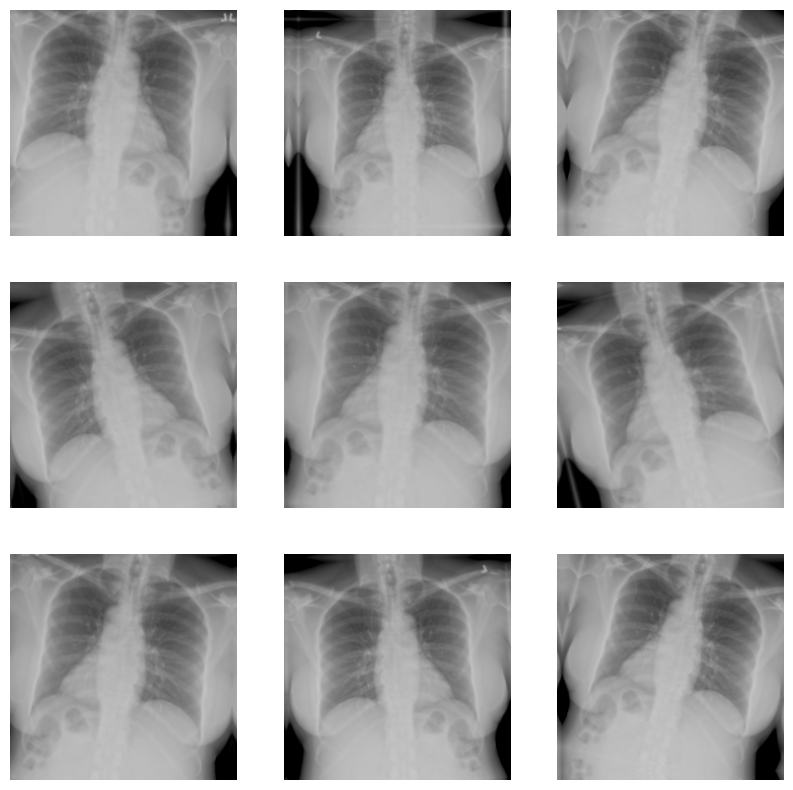

In [ ]:
import matplotlib.pyplot as plt

for image, _ in train_ds.take(1):
  plt.figure(figsize=(10, 10))
  first_image = image[0]
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    augmented_image = data_augmentation(tf.expand_dims(first_image, 0))
    plt.imshow(augmented_image[0] / 255)
    plt.axis('off')

In [20]:
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    
    layers.Rescaling(1./255),
    data_augmentation,

    base_model,
    
    layers.GlobalAveragePooling2D(),
   
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5), # Regularization to prevent overfitting
    
    layers.Dense(4, activation='softmax')
])

In [21]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


model.summary()


# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds, # evaluating against val dataset
    epochs=10
)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_2 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,780,868 (56.38 MB)

 Trainable params: 66,180 (258.52 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

Epoch 1/10


2026-03-22 18:48:21.537918: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


408/408 ━━━━━━━━━━━━━━━━━━━━ 161s 388ms/step - accuracy: 0.6632 - loss: 0.7889 - val_accuracy: 0.8371 - val_loss: 0.4191
Epoch 2/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 153s 376ms/step - accuracy: 0.8218 - loss: 0.4449 - val_accuracy: 0.8765 - val_loss: 0.3245
Epoch 3/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 149s 364ms/step - accuracy: 0.8479 - loss: 0.3762 - val_accuracy: 0.8778 - val_loss: 0.3245
Epoch 4/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 152s 371ms/step - accuracy: 0.8651 - loss: 0.3399 - val_accuracy: 0.9041 - val_loss: 0.2690
Epoch 5/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 161s 395ms/step - accuracy: 0.8736 - loss: 0.3190 - val_accuracy: 0.8936 - val_loss: 0.2913
Epoch 6/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 171s 418ms/step - accuracy: 0.8774 - loss: 0.3084 - val_accuracy: 0.9159 - val_loss: 0.2490
Epoch 7/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 162s 395ms/step - accuracy: 0.8816 - loss: 0.3017 - val_accuracy: 0.8975 - val_loss: 0.2876
Epoch 8/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 165s 405ms/step - accuracy: 0.8790 - loss: 0.30

In [27]:
# Save the model
model.save('CXC105.keras')
print("Model saved successfully!")

Model saved successfully!


In [28]:
# Evaludate against test data
results = model.evaluate(test_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

48/48 ━━━━━━━━━━━━━━━━━━━━ 17s 341ms/step - accuracy: 0.9024 - loss: 0.2232
Test Loss: 0.22321562469005585
Test Accuracy: 90.24%


2026-03-22 19:26:25.416619: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


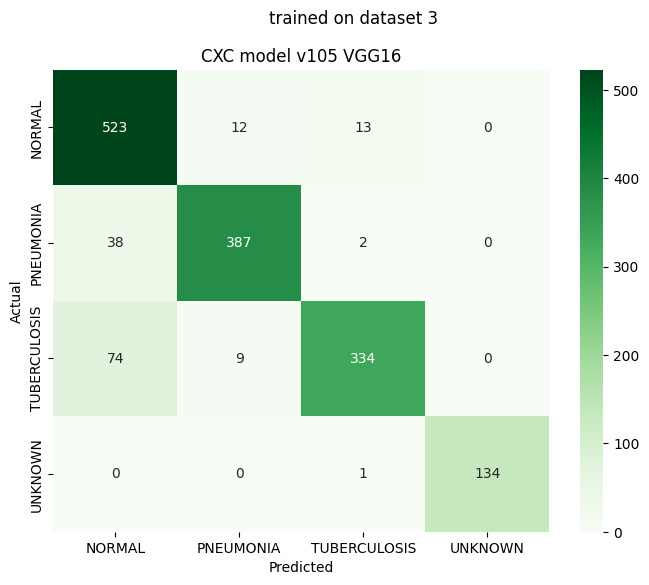

              precision    recall  f1-score   support

      NORMAL       0.82      0.95      0.88       548
   PNEUMONIA       0.95      0.91      0.93       427
TUBERCULOSIS       0.95      0.80      0.87       417
     UNKNOWN       1.00      0.99      1.00       135

    accuracy                           0.90      1527
   macro avg       0.93      0.91      0.92      1527
weighted avg       0.91      0.90      0.90      1527



In [32]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Get all predictions and true labels
y_pred = []
y_true = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(labels, axis=1))

# Generate the Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
class_names = test_ds.class_names

# Plot them in heat map
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', 
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('CXC model v105 VGG16')
plt.suptitle("trained on dataset 3")
plt.show()

# Print Precision, Recall, and F1-Score
print(classification_report(y_true, y_pred, target_names=class_names))

In [25]:
results = model.evaluate(val_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

24/24 ━━━━━━━━━━━━━━━━━━━━ 7s 297ms/step - accuracy: 0.9028 - loss: 0.2606
Test Loss: 0.2605748772621155
Test Accuracy: 90.28%
